   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 7.4 MB/s eta 0:00:00


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 32.3MB            

model.safetensors: downloading bytes:           |  0.00B            

loading annotations into memory...
Done (t=0.07s)
creating index...
index created!
Starting Natural Training on cuda using backbone: densenet121
Epoch [10/80] - Loss: 1.0309
Epoch [20/80] - Loss: 0.8190
Epoch [30/80] - Loss: 0.4565
Epoch [40/80] - Loss: 0.3189
Epoch [50/80] - Loss: 0.1426
Epoch [60/80] - Loss: 0.1026
Epoch [70/80] - Loss: 0.1014
Epoch [80/80] - Loss: 0.0751

--- DENSENET121 Evaluation Metrics ---
Average BCE Loss   : 0.0023
Average Dice Loss  : 0.0585
Dice Score Accuracy: 94.15%

Generating Visual Overlays for densenet121...


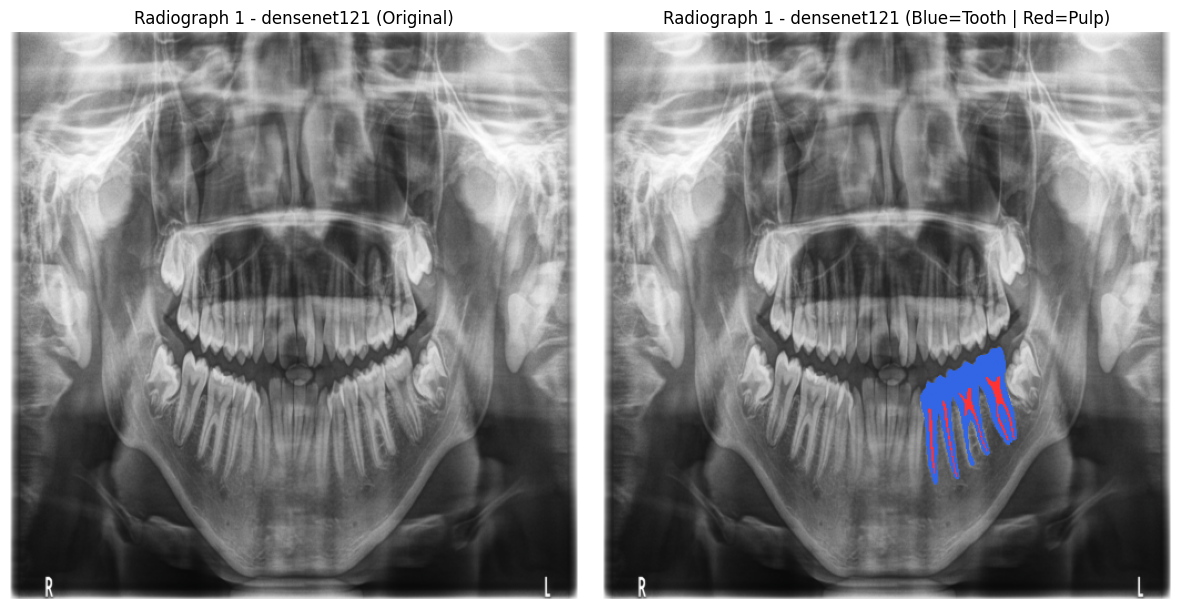

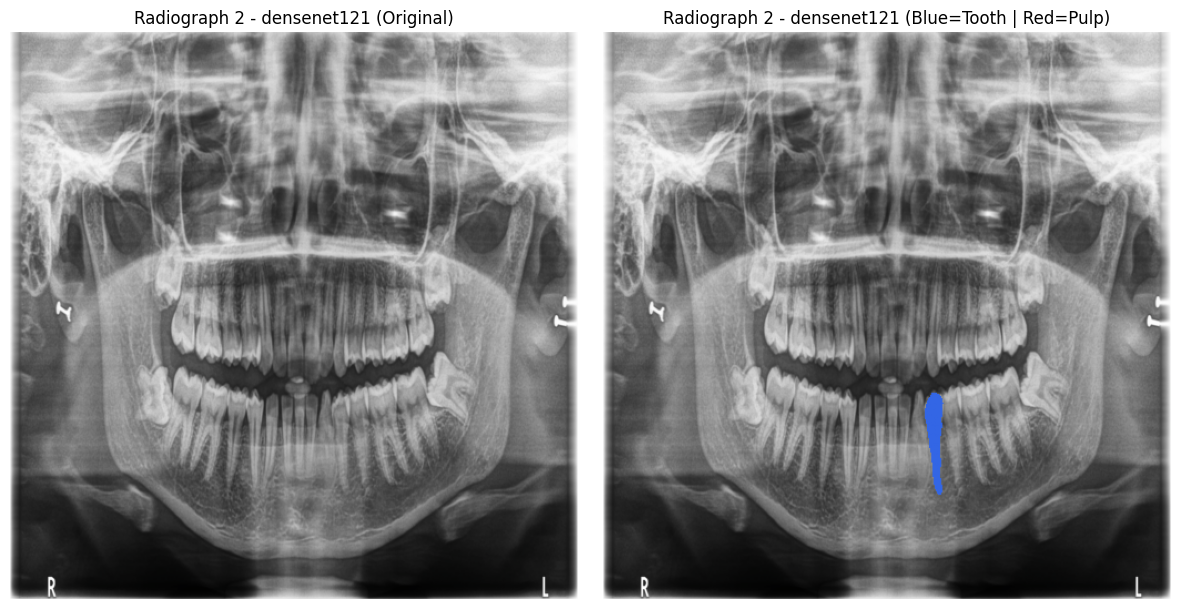

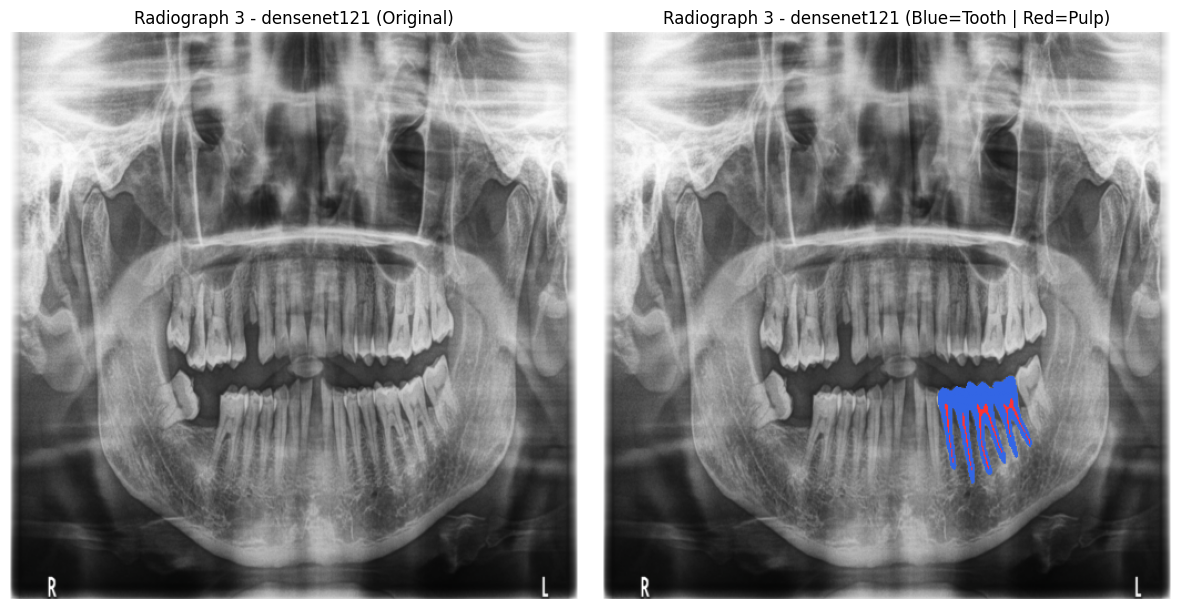

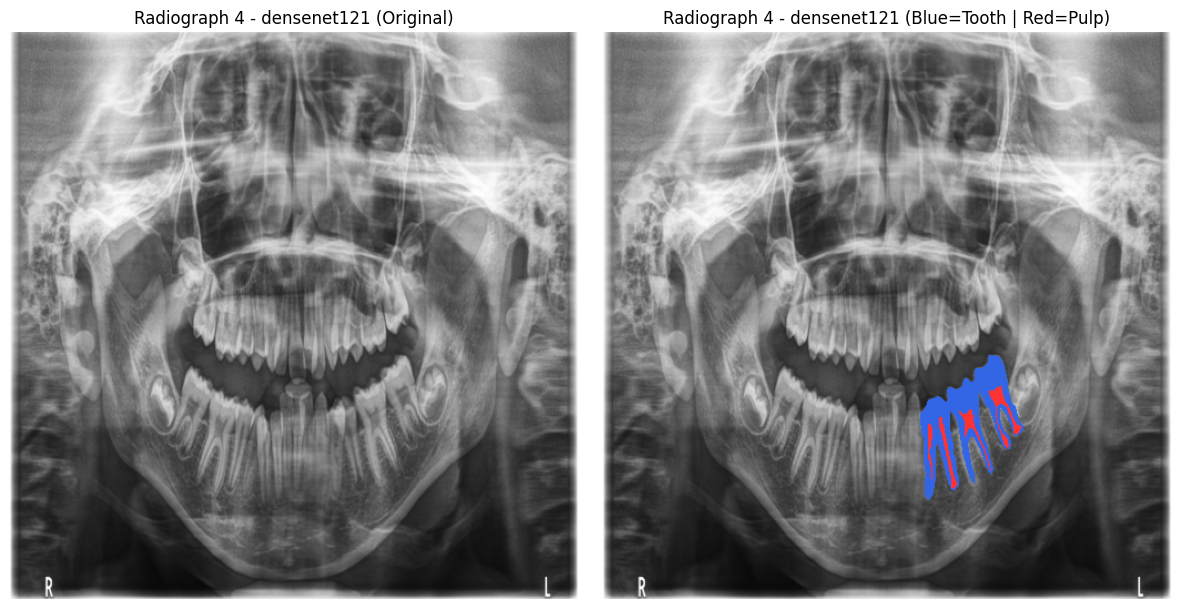

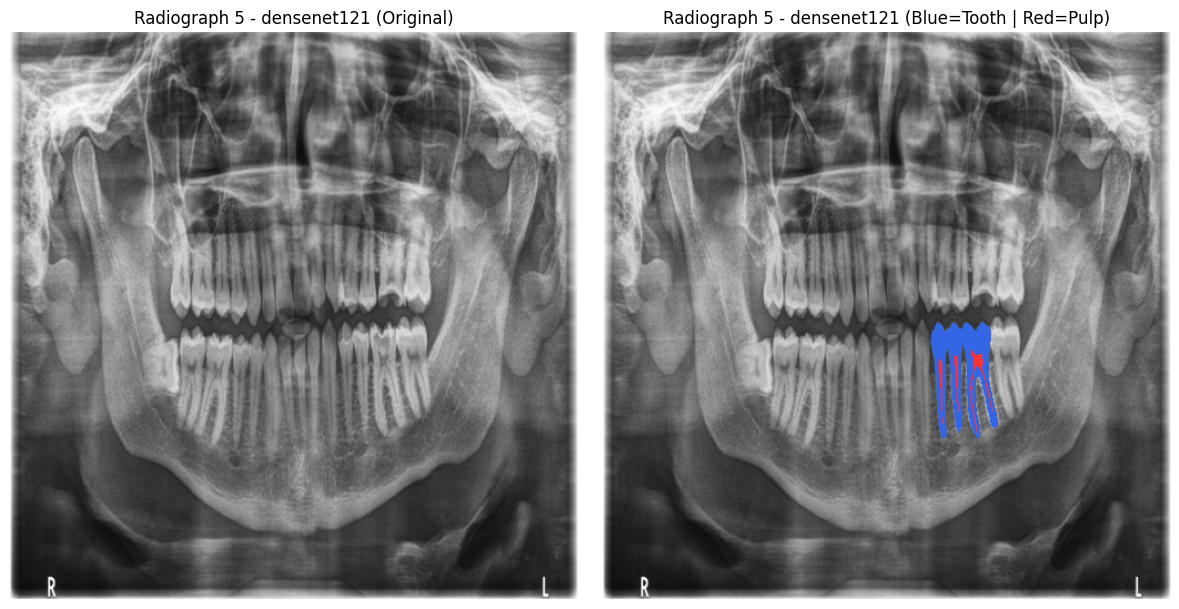

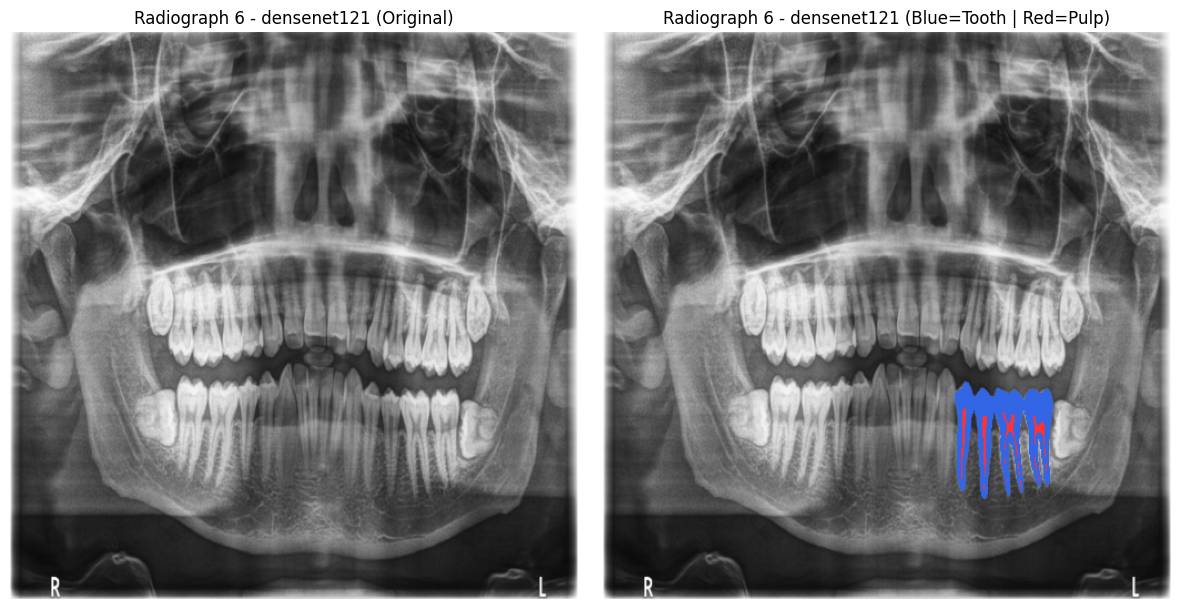

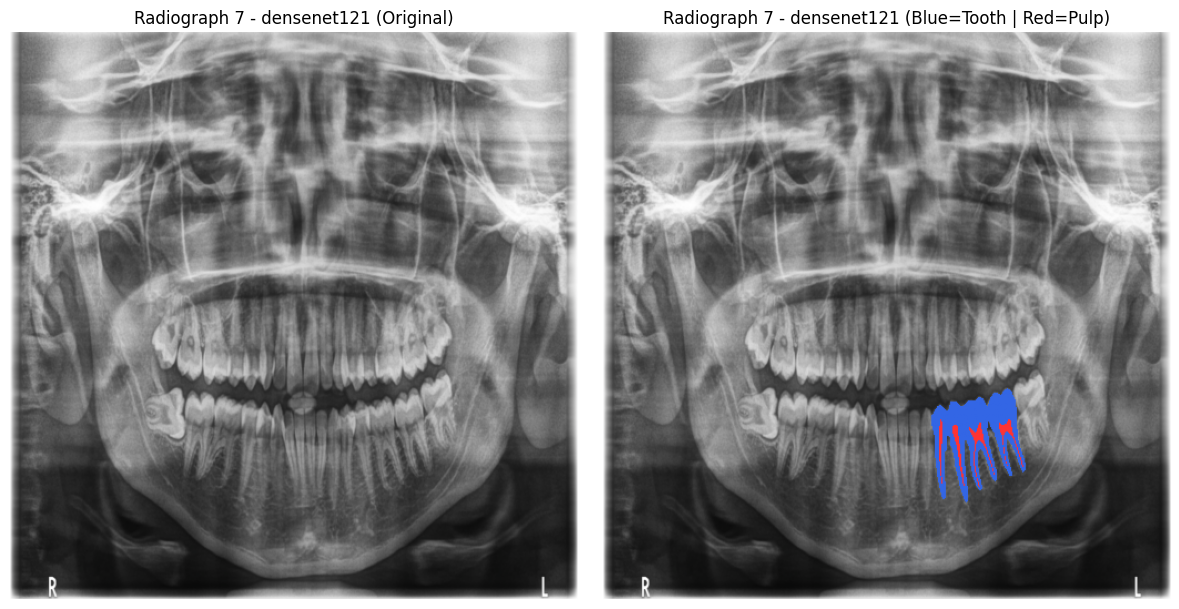

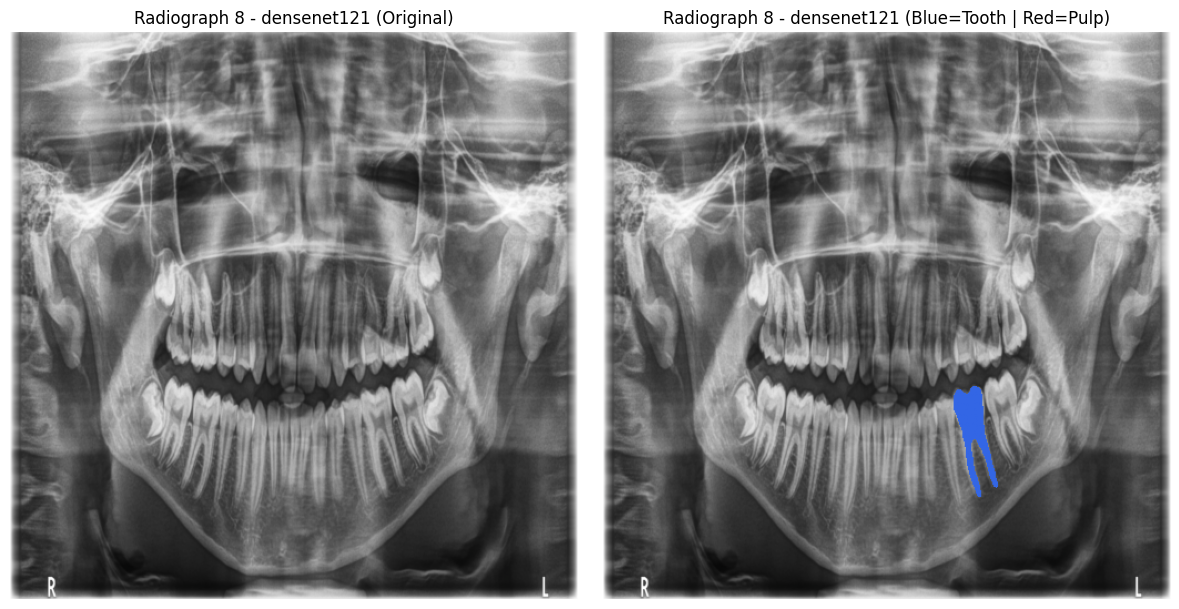

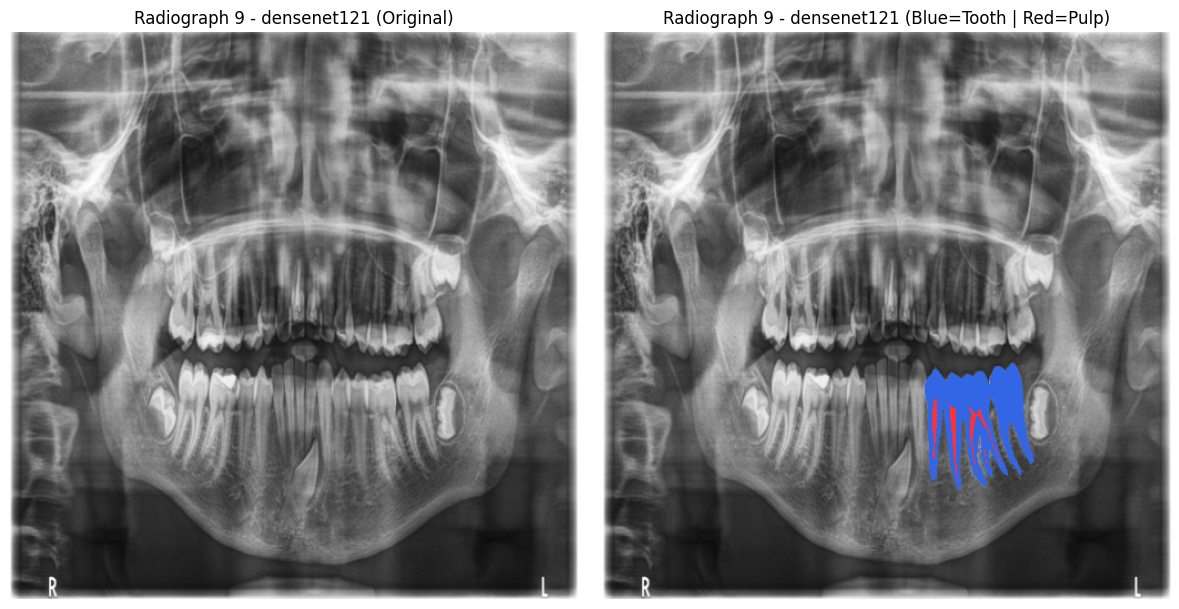

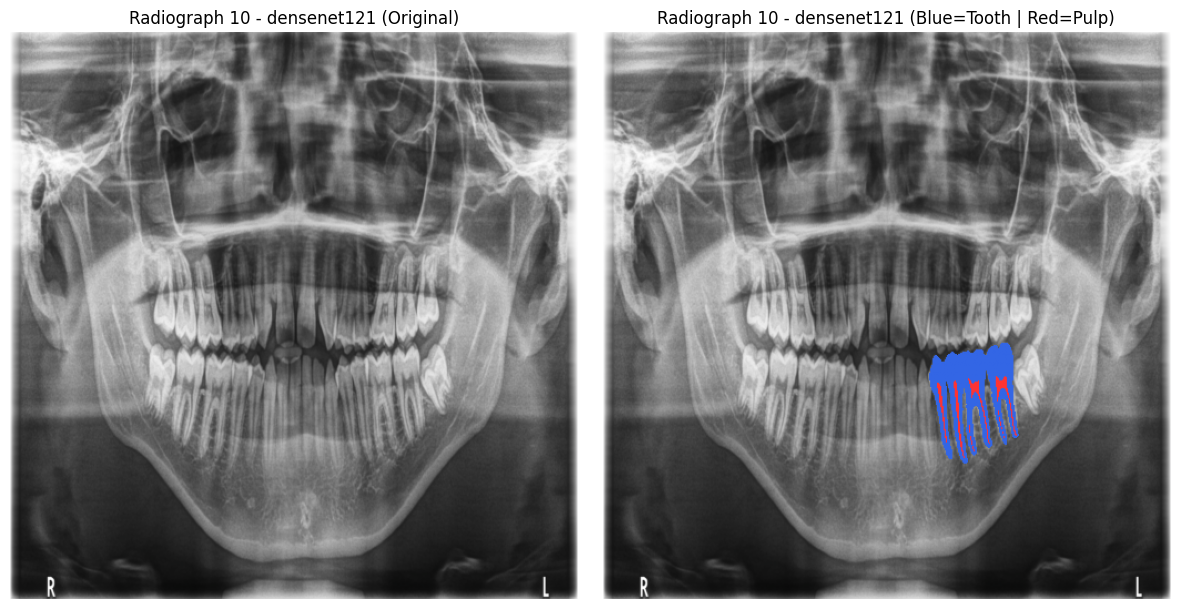

In [1]:
!pip install segmentation-models-pytorch
import os
import json
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as T
import matplotlib.pyplot as plt
from pycocotools.coco import COCO
import segmentation_models_pytorch as smp

# ==========================================
# 1. KAGGLE PATH CONFIGURATION
# ==========================================
INPUT_DIR = '/kaggle/input/datasets/preemalsimonapinto/dental-opg-data/OPG Age Analysis.coco-segmentation/train' 
json_path = os.path.join(INPUT_DIR, '_annotations.coco.json')
img_dir = INPUT_DIR

assert os.path.exists(json_path), f"Error: Cannot find annotation file at {json_path}"
assert os.path.exists(img_dir), f"Error: Cannot find image directory at {img_dir}"


# ==========================================
# 2. MULTI-CLASS DATASET CLASS
# ==========================================
class DentalMultiClassDataset(Dataset):
    def __init__(self, annotation_file, img_dir, transform=None):
        self.coco = COCO(annotation_file)
        self.ids = list(self.coco.imgs.keys())
        self.img_dir = img_dir
        self.transform = transform

        self.pulp_cat_ids = [1, 3, 5, 7, 9]
        self.tooth_cat_ids = [2, 4, 6, 8, 10, 11]

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, index):
        img_id = self.ids[index]
        ann_ids = self.coco.getAnnIds(imgIds=img_id)
        anns = self.coco.loadAnns(ann_ids)

        img_info = self.coco.loadImgs(img_id)[0]
        img_full_path = os.path.join(self.img_dir, img_info['file_name'])

        image = Image.open(img_full_path).convert("RGB")
        h, w = img_info['height'], img_info['width']

        mask = np.zeros((2, h, w), dtype=np.float32)

        for ann in anns:
            cat_id = ann['category_id']
            ann_mask = self.coco.annToMask(ann)

            if cat_id in self.tooth_cat_ids:
                mask[0] = np.maximum(mask[0], ann_mask)
            elif cat_id in self.pulp_cat_ids:
                mask[1] = np.maximum(mask[1], ann_mask)

        if self.transform:
            image = self.transform(image)
            mask = torch.from_numpy(mask)
            mask = T.functional.resize(mask, [512, 512], interpolation=T.InterpolationMode.NEAREST)

        return image, mask


# ==========================================
# 3. NORMALIZED WEIGHTED DICE + BCE LOSS
# ==========================================
class NormalizedWeightedDiceBCELoss(nn.Module):
    def __init__(self, tooth_weight=1.0, pulp_weight=2.0):
        super(NormalizedWeightedDiceBCELoss, self).__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.tooth_weight = tooth_weight
        self.pulp_weight = pulp_weight
        self.total_weight = tooth_weight + pulp_weight

    def forward(self, inputs, targets, smooth=1):
        bce_tooth = self.bce(inputs[:, 0], targets[:, 0])
        bce_pulp = self.bce(inputs[:, 1], targets[:, 1])
        bce_loss = ((self.tooth_weight * bce_tooth) + (self.pulp_weight * bce_pulp)) / self.total_weight
        
        probs = torch.sigmoid(inputs)
        
        p_tooth = probs[:, 0].contiguous().view(-1)
        t_tooth = targets[:, 0].contiguous().view(-1)
        dice_tooth = 1 - (2. * (p_tooth * t_tooth).sum() + smooth) / (p_tooth.sum() + t_tooth.sum() + smooth)
        
        p_pulp = probs[:, 1].contiguous().view(-1)
        t_pulp = targets[:, 1].contiguous().view(-1)
        dice_pulp = 1 - (2. * (p_pulp * t_pulp).sum() + smooth) / (p_pulp.sum() + t_pulp.sum() + smooth)
        
        dice_loss = ((self.tooth_weight * dice_tooth) + (self.pulp_weight * dice_pulp)) / self.total_weight
        
        return bce_loss + dice_loss


# ==========================================
# 4. DENSENET121 MODEL SETUP
# ==========================================
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SELECTED_ENCODER = "densenet121" 

model = smp.Unet(
    encoder_name=SELECTED_ENCODER,      
    encoder_weights="imagenet",   
    in_channels=3,                
    classes=2,                    
).to(device)

criterion = NormalizedWeightedDiceBCELoss(tooth_weight=1.0, pulp_weight=2.0)
optimizer = optim.Adam(model.parameters(), lr=0.0005)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=10)


# ==========================================
# 5. INITIALIZATION & TRAINING (80 Epochs)
# ==========================================
transform = T.Compose([
    T.Resize((512, 512)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

dataset = DentalMultiClassDataset(
    annotation_file=json_path,
    img_dir=img_dir,
    transform=transform
)

data_loader = DataLoader(dataset, batch_size=2, shuffle=True)

epochs = 80
print(f"Starting Natural Training on {device} using backbone: {SELECTED_ENCODER}")

model.train()
for epoch in range(epochs):
    running_loss = 0.0
    for images, masks in data_loader:
        images, masks = images.to(device), masks.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(data_loader)
    scheduler.step(epoch_loss)

    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{epochs}] - Loss: {epoch_loss:.4f}")


# ==========================================
# 6. EVALUATION METRICS
# ==========================================
model.eval()
bce_criterion = nn.BCEWithLogitsLoss()

total_bce, total_dice, total_dice_score = 0.0, 0.0, 0.0

with torch.no_grad():
    for images, masks in data_loader:
        images, masks = images.to(device), masks.to(device)
        outputs = model(images)

        bce_loss = bce_criterion(outputs, masks)

        probs = torch.sigmoid(outputs)
        smooth = 1.0
        intersection = (probs.view(-1) * masks.view(-1)).sum()
        union = probs.view(-1).sum() + masks.view(-1).sum()

        dice_loss = 1.0 - (2. * intersection + smooth) / (union + smooth)
        dice_score = (2. * intersection + smooth) / (union + smooth)

        total_bce += bce_loss.item()
        total_dice += dice_loss.item()
        total_dice_score += dice_score.item()

num_batches = len(data_loader)
print(f"\n--- {SELECTED_ENCODER.upper()} Evaluation Metrics ---")
print(f"Average BCE Loss   : {total_bce / num_batches:.4f}")
print(f"Average Dice Loss  : {total_dice / num_batches:.4f}")
print(f"Dice Score Accuracy: {(total_dice_score / num_batches) * 100:.2f}%")


# ==========================================
# 7. SIDE-BY-SIDE VISUAL OVERLAYS
# ==========================================
print(f"\nGenerating Visual Overlays for {SELECTED_ENCODER}...")
image_counter = 1

with torch.no_grad():
    for images, masks in data_loader:
        images = images.to(device)
        outputs = torch.sigmoid(model(images))
        
        for i in range(len(images)):
            img_np = images[i].cpu().numpy().transpose(1, 2, 0)
            img_np = img_np * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
            img_np = np.clip(img_np, 0, 1)
            
            pred = outputs[i].cpu().numpy()
            tooth_mask = pred[0] > 0.5
            pulp_mask  = pred[1] > 0.5  # Natural threshold
            
            overlay = img_np.copy()
            overlay[tooth_mask] = [0.2, 0.4, 0.9]  # Blue for tooth
            overlay[pulp_mask]  = [1.0, 0.2, 0.2]  # Red for pulp
            
            fig, ax = plt.subplots(1, 2, figsize=(12, 6))
            ax[0].imshow(img_np)
            ax[0].set_title(f"Radiograph {image_counter} - {SELECTED_ENCODER} (Original)")
            ax[0].axis('off')
            
            ax[1].imshow(overlay)
            ax[1].set_title(f"Radiograph {image_counter} - {SELECTED_ENCODER} (Blue=Tooth | Red=Pulp)")
            ax[1].axis('off')
            
            plt.tight_layout()
            plt.show()
            
            image_counter += 1

In [2]:
import os

save_path = '/kaggle/working/densenet121_dental_unet.pth'
torch.save(model.state_dict(), save_path)
print(f"DenseNet121 weights successfully saved to: {save_path}")

DenseNet121 weights successfully saved to: /kaggle/working/densenet121_dental_unet.pth
